In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering

In [21]:
df = pd.read_csv("Universities.csv")

In [22]:
df.head()

,Univ,SAT,Top10,Accept,SFRatio,Expenses,GradRate
0,Brown,1310,89,22,13,22704,94
1,CalTech,1415,100,25,6,63575,81
2,CMU,1260,62,59,9,25026,72
3,Columbia,1310,76,24,12,31510,88
4,Cornell,1280,83,33,13,21864,90


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Univ      25 non-null     object
 1   SAT       25 non-null     int64 
 2   Top10     25 non-null     int64 
 3   Accept    25 non-null     int64 
 4   SFRatio   25 non-null     int64 
 5   Expenses  25 non-null     int64 
 6   GradRate  25 non-null     int64 
dtypes: int64(6), object(1)
memory usage: 1.5+ KB


In [24]:
df.describe()

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
count,25.000000,25.000000,25.000000,25.00000,25.000000,25.000000
mean,1266.440000,76.480000,39.200000,12.72000,27388.000000,86.720000
std,108.359771,19.433905,19.727308,4.06735,14424.883165,9.057778
min,1005.000000,28.000000,14.000000,6.00000,8704.000000,67.000000
25%,1240.000000,74.000000,24.000000,11.00000,15140.000000,81.000000
50%,1285.000000,81.000000,36.000000,12.00000,27553.000000,90.000000
75%,1340.000000,90.000000,50.000000,14.00000,34870.000000,94.000000
max,1415.000000,100.000000,90.000000,25.00000,63575.000000,97.000000


In [25]:
df['Univ'].unique()

array(['Brown', 'CalTech', 'CMU', 'Columbia', 'Cornell', 'Dartmouth',
       'Duke', 'Georgetown', 'Harvard', 'JohnsHopkins', 'MIT',
       'Northwestern', 'NotreDame', 'PennState', 'Princeton', 'Purdue',
       'Stanford', 'TexasA&M', 'UCBerkeley', 'UChicago', 'UMichigan',
       'UPenn', 'UVA', 'UWisconsin', 'Yale'], dtype=object)

In [26]:
df.drop(['Univ'],axis=1,inplace=True)

In [27]:
df.corr()

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
SAT,1.000000,0.922522,-0.885850,-0.812552,0.778976,0.747712
Top10,0.922522,1.000000,-0.859181,-0.643435,0.611467,0.745942
Accept,-0.885850,-0.859181,1.000000,0.631664,-0.558439,-0.819550
SFRatio,-0.812552,-0.643435,0.631664,1.000000,-0.781839,-0.560922
Expenses,0.778976,0.611467,-0.558439,-0.781839,1.000000,0.393591
GradRate,0.747712,0.745942,-0.819550,-0.560922,0.393591,1.000000


In [28]:
df.head()

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
0,1310,89,22,13,22704,94
1,1415,100,25,6,63575,81
2,1260,62,59,9,25026,72
3,1310,76,24,12,31510,88
4,1280,83,33,13,21864,90


In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler



In [30]:
std1 = MinMaxScaler()
df_std = pd.DataFrame(std1.fit_transform(df),columns = df.columns)

In [31]:
std2 = StandardScaler()
df_std_normaliz = pd.DataFrame(std2.fit_transform(df),columns=df.columns)

In [32]:
df_std

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
0,0.743902,0.847222,0.105263,0.368421,0.255144,0.900000
1,1.000000,1.000000,0.144737,0.000000,1.000000,0.466667
2,0.621951,0.472222,0.592105,0.157895,0.297461,0.166667
3,0.743902,0.666667,0.131579,0.315789,0.415629,0.700000
4,0.670732,0.763889,0.250000,0.368421,0.239835,0.766667
5,0.817073,0.847222,0.118421,0.210526,0.427512,0.933333
6,0.756098,0.861111,0.210526,0.315789,0.416996,0.933333
7,0.609756,0.638889,0.131579,0.315789,0.208161,0.833333
8,0.963415,0.875000,0.000000,0.263158,0.561699,1.000000
9,0.731707,0.652778,0.394737,0.052632,0.910991,0.666667


In [33]:
df

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
0,1310,89,22,13,22704,94
1,1415,100,25,6,63575,81
2,1260,62,59,9,25026,72
3,1310,76,24,12,31510,88
4,1280,83,33,13,21864,90
5,1340,89,23,10,32162,95
6,1315,90,30,12,31585,95
7,1255,74,24,12,20126,92
8,1400,91,14,11,39525,97
9,1305,75,44,7,58691,87


For min max scaler


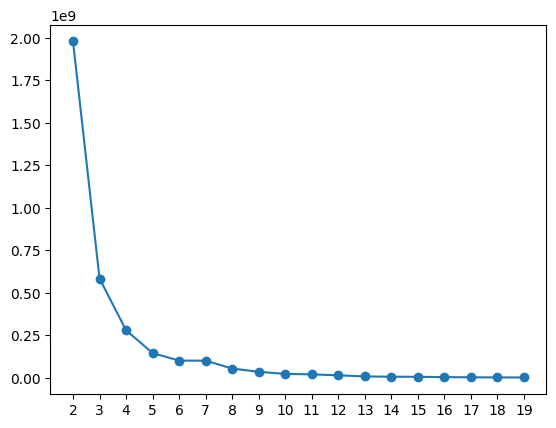

In [34]:
print("For min max scaler")
wcc=[]
for k in range(2,20):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(df)
    
    wcc.append(kmeans.inertia_)
plt.xticks(range(2,20))

plt.plot(range(2,20),wcc,marker='o')


using normalization


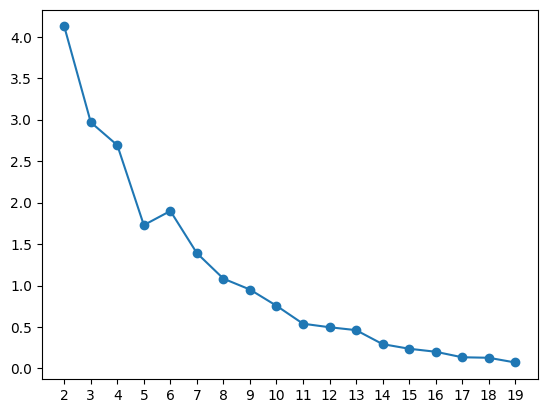

In [35]:
print("using normalization")
wcc=[]
for k in range(2,20):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(df_std)
    
    wcc.append(kmeans.inertia_)
plt.xticks(range(2,20))

plt.plot(range(2,20),wcc,marker='o')

In [36]:
# from sklearn.cluster import KMeans
print("using min max ")
k = 5
kmeans = KMeans(n_clusters=k)
kmeans.fit(df_std)
df['awards_prediction']=kmeans.labels_
from sklearn.metrics import silhouette_score

# find hte labels of every data point
labels = kmeans.labels_

# finding silhouette score

score = silhouette_score(df_std,labels)
print(f"Silhouette score = {score:.2f}")

using min max 
Silhouette score = 0.32


In [37]:
print("using std normalization")
k = 5
kmeans = KMeans(n_clusters=k)
kmeans.fit(df_std_normaliz)
df['awards_prediction']=kmeans.labels_
from sklearn.metrics import silhouette_score

# find hte labels of every data point
labels = kmeans.labels_

# finding silhouette score

score = silhouette_score(df_std,labels)
print(f"Silhouette score = {score:.2f}")

using std normalization
Silhouette score = 0.28


In [38]:
# df['awards_prediction'].unique()

In [39]:

from sklearn.cluster import AgglomerativeClustering
cluster_info = AgglomerativeClustering(n_clusters=5)
cluster_info.fit(df_std)

,n_clusters,5
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


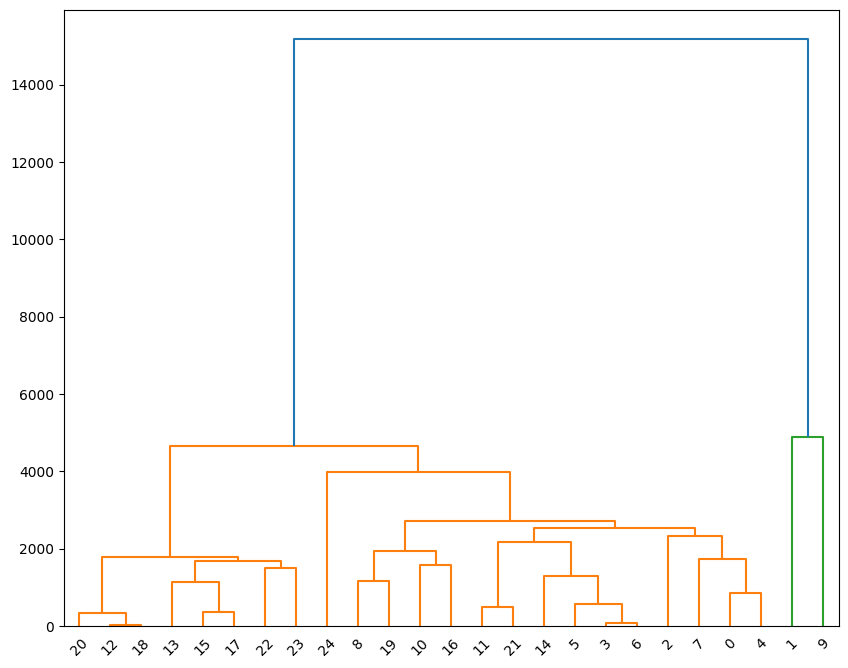

In [40]:
from scipy.cluster import hierarchy

# get the linkage information
linkage = hierarchy.linkage(df, 'single')
plt.figure(figsize=(10,8))
# create a dendrogram using linkage data
dendrogram = hierarchy.dendrogram(linkage)

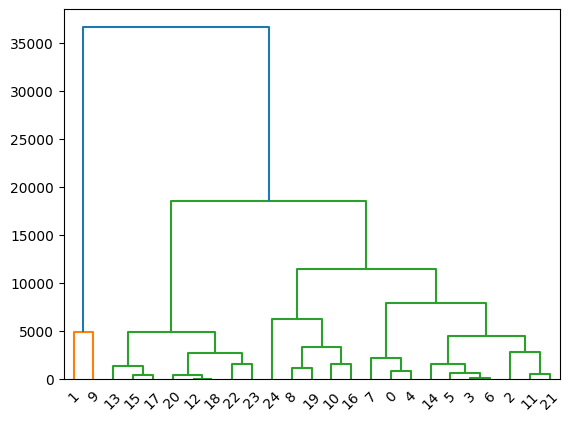

In [41]:
linkage = hierarchy.linkage(df, 'average')
dendrogram = hierarchy.dendrogram(linkage)

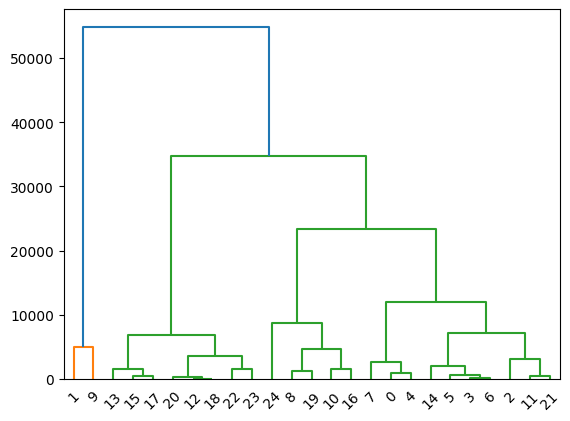

In [42]:
linkage = hierarchy.linkage(df, 'complete')
dendrogram = hierarchy.dendrogram(linkage)